## 1. Import Required Libraries

Libraries for text processing, deterministic hashing, statistics, data handling, visualization, and Colab upload.

In [ ]:
import re
import hashlib
import statistics
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Helper Functions

The text is normalized into words and SHA-256 provides deterministic 64-bit hash values.

In [ ]:
def tokenize(text):
    return re.findall(r'[a-z0-9]+', str(text).lower())

def hash_to_uint64(value, seed=0):
    data = f'{seed}:{value}'.encode('utf-8')
    digest = hashlib.sha256(data).digest()
    return int.from_bytes(digest[:8], byteorder='big', signed=False)

def trailing_zero_count(x):
    if x == 0:
        return 64
    return (x & -x).bit_length() - 1

def exact_distinct_count(stream):
    return len(set(stream))

print("Helper functions defined successfully.")


Helper functions defined successfully.


## 3. Basic Flajolet-Martin (FM) Algorithm

For each word:
- Hash the word.
- Count trailing zero bits.
- Store the maximum value `R`.
- Estimate cardinality using:

**Estimate ≈ 2^R / φ**

where **φ = 0.77351**.


In [ ]:
PHI = 0.77351

def fm_algorithm(stream, seed=0):
    R = 0
    for word in stream:
        h = hash_to_uint64(word, seed)
        R = max(R, trailing_zero_count(h))
    return (2 ** R) / PHI, R

print("Basic FM algorithm defined.")


Basic FM algorithm defined.


## 4. Modified FM Algorithm

The modified version uses multiple independent hash functions. Each produces an FM estimate, and the **median** of the estimates becomes the final estimate. This reduces the influence of an unusually large register value.


In [ ]:
def modified_fm_algorithm(stream, num_hashes=32):
    estimates = []
    registers = []
    for seed in range(num_hashes):
        estimate, R = fm_algorithm(stream, seed)
        estimates.append(estimate)
        registers.append(R)
    return statistics.median(estimates), estimates, registers

print("Modified FM algorithm defined.")


Modified FM algorithm defined.


## 5. Create a Different Text File

A new text file is created instead of using the dataset from the reference notebook. You can later replace it with any other `.txt` file.


In [ ]:
sample_text = 'data science uses data for analysis and prediction.\nmachine learning finds patterns in data and supports intelligent decisions.\ndeep learning uses neural networks to learn complex patterns from data.\nstream processing handles data continuously as new information arrives.\nbig data systems process large volumes of information efficiently.\ndata streams may contain repeated words and repeated events.\nstream algorithms estimate useful statistics without storing every item.\nhashing converts data items into values that can be processed efficiently.\nthe flajolet martin algorithm estimates the number of distinct elements in a stream.\nmodified flajolet martin improves stability by using multiple hash functions.\nprobabilistic algorithms trade exactness for lower memory requirements.\nefficient algorithms are important when data streams become very large.'

with open("different_text_stream.txt", "w", encoding="utf-8") as f:
    f.write(sample_text)

print("Created: different_text_stream.txt")
print("Characters:", len(sample_text))
print(sample_text[:500])


Created: different_text_stream.txt
Characters: 854
data science uses data for analysis and prediction.
machine learning finds patterns in data and supports intelligent decisions.
deep learning uses neural networks to learn complex patterns from data.
stream processing handles data continuously as new information arrives.
big data systems process large volumes of information efficiently.
data streams may contain repeated words and repeated events.
stream algorithms estimate useful statistics without storing every item.
hashing converts data items


## 6. Upload Your Own Different Text File (Optional)

Run this cell if you want to replace the generated text with your own `.txt` file.


In [ ]:
uploaded = files.upload()

if uploaded:
    file_name = next(iter(uploaded))
    if not file_name.lower().endswith(".txt"):
        raise ValueError("Please upload a .txt file.")
    with open(file_name, "r", encoding="utf-8", errors="ignore") as f:
        file_text = f.read()
    print("Using uploaded file:", file_name)
else:
    file_name = "different_text_stream.txt"
    with open(file_name, "r", encoding="utf-8") as f:
        file_text = f.read()
    print("Using generated file:", file_name)

print("Characters:", len(file_text))


Saving different_text_stream.txt to different_text_stream (1).txt
Using uploaded file: different_text_stream (1).txt
Characters: 854


## 7. Convert Text File into a Word Stream

The complete text is processed sequentially as a stream. The exact distinct count is calculated only for evaluating the probabilistic algorithms.


In [ ]:
stream = tokenize(file_text)
exact_count = exact_distinct_count(stream)

print("Total words in stream:", len(stream))
print("Exact distinct words:", exact_count)
print("First 40 stream words:", stream[:40])


Total words in stream: 117
Exact distinct words: 89
First 40 stream words: ['data', 'science', 'uses', 'data', 'for', 'analysis', 'and', 'prediction', 'machine', 'learning', 'finds', 'patterns', 'in', 'data', 'and', 'supports', 'intelligent', 'decisions', 'deep', 'learning', 'uses', 'neural', 'networks', 'to', 'learn', 'complex', 'patterns', 'from', 'data', 'stream', 'processing', 'handles', 'data', 'continuously', 'as', 'new', 'information', 'arrives', 'big', 'data']


## 8. Word Frequency Analysis

This shows repeated and unique words in the input stream. This exact frequency table is for analysis only and is not required by FM.

In [ ]:
word_counts = pd.Series(stream).value_counts()
print("Number of unique words:", len(word_counts))
display(word_counts.head(15).rename("Frequency").to_frame())


Number of unique words: 89


,Frequency
data,9
and,3
stream,3
algorithms,3
learning,2
patterns,2
in,2
for,2
uses,2
the,2


## 9. Run Basic FM on the Different Text Stream

In [ ]:
fm_estimate, fm_R = fm_algorithm(stream)

print("--- Basic FM Algorithm ---")
print("Maximum trailing-zero position (R):", fm_R)
print("Estimated distinct words:", round(fm_estimate, 2))
print("Exact distinct words:", exact_count)
print("Absolute error:", round(abs(fm_estimate - exact_count), 2))
print("Error percentage:", round(abs(fm_estimate - exact_count) / exact_count * 100, 2), "%")


--- Basic FM Algorithm ---
Maximum trailing-zero position (R): 9
Estimated distinct words: 661.92
Exact distinct words: 89
Absolute error: 572.92
Error percentage: 643.73 %


## 10. Run Modified FM with Multiple Hash Functions

In [ ]:
modified_estimate, all_estimates, all_registers = modified_fm_algorithm(stream, num_hashes=32)

print("--- Modified FM Algorithm ---")
print("Number of hash functions:", len(all_estimates))
print("Median estimated distinct words:", round(modified_estimate, 2))
print("Exact distinct words:", exact_count)
print("Absolute error:", round(abs(modified_estimate - exact_count), 2))
print("Error percentage:", round(abs(modified_estimate - exact_count) / exact_count * 100, 2), "%")


--- Modified FM Algorithm ---
Number of hash functions: 32
Median estimated distinct words: 82.74
Exact distinct words: 89
Absolute error: 6.26
Error percentage: 7.03 %


## 11. Compare Exact Count, Basic FM and Modified FM

In [ ]:
comparison = pd.DataFrame({
    "Method": ["Exact Count", "Basic FM", "Modified FM"],
    "Distinct Words": [exact_count, fm_estimate, modified_estimate]
})
comparison["Absolute Error"] = [
    0,
    abs(fm_estimate - exact_count),
    abs(modified_estimate - exact_count)
]
comparison["Error %"] = comparison["Absolute Error"] / exact_count * 100
display(comparison.round(2))


,Method,Distinct Words,Absolute Error,Error %
0,Exact Count,89.00,0.00,0.00
1,Basic FM,661.92,572.92,643.73
2,Modified FM,82.74,6.26,7.03


## 12. Visualize the Three Results

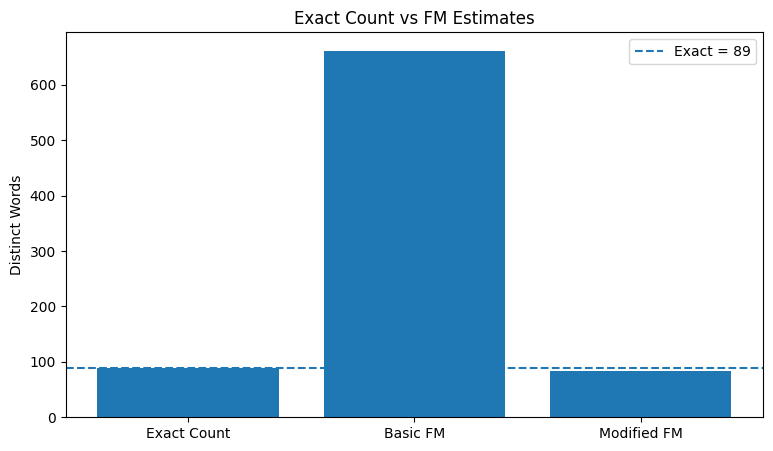

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(comparison["Method"], comparison["Distinct Words"])
plt.axhline(exact_count, linestyle="--", label=f"Exact = {exact_count}")
plt.ylabel("Distinct Words")
plt.title("Exact Count vs FM Estimates")
plt.legend()
plt.show()


## 13. Inspect the 32 Modified-FM Estimates

Different hash functions can produce different estimates. The median is used as the final Modified FM result.

In [ ]:
estimate_df = pd.DataFrame({
    "Hash Seed": range(len(all_estimates)),
    "Maximum R": all_registers,
    "FM Estimate": all_estimates
})
display(estimate_df.round(2))

print("Mean estimate:", round(statistics.mean(all_estimates), 2))
print("Median estimate:", round(statistics.median(all_estimates), 2))
print("Minimum estimate:", round(min(all_estimates), 2))
print("Maximum estimate:", round(max(all_estimates), 2))


,Hash Seed,Maximum R,FM Estimate
0,0,9,661.92
1,1,6,82.74
2,2,9,661.92
3,3,5,41.37
4,4,7,165.48
5,5,6,82.74
6,6,5,41.37
7,7,6,82.74
8,8,5,41.37
9,9,9,661.92


Mean estimate: 197.8
Median estimate: 82.74
Minimum estimate: 41.37
Maximum estimate: 661.92


## 14. Plot Multiple Hash-Function Estimates

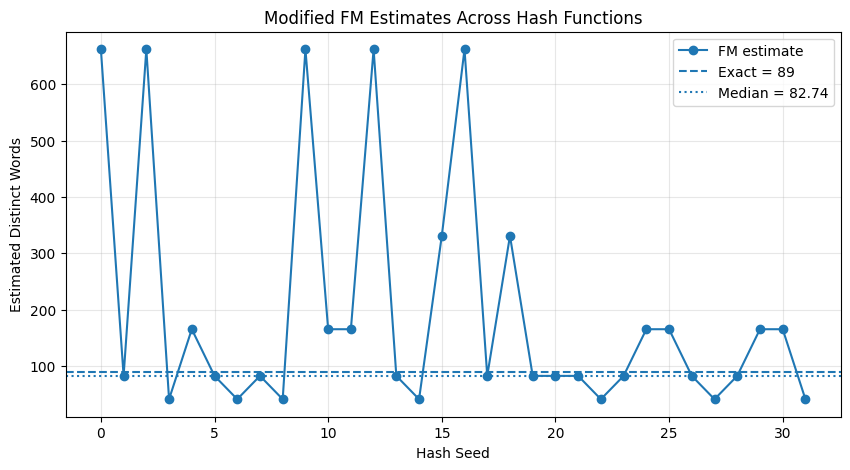

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(estimate_df["Hash Seed"], estimate_df["FM Estimate"], marker="o", label="FM estimate")
plt.axhline(exact_count, linestyle="--", label=f"Exact = {exact_count}")
plt.axhline(modified_estimate, linestyle=":", label=f"Median = {modified_estimate:.2f}")
plt.xlabel("Hash Seed")
plt.ylabel("Estimated Distinct Words")
plt.title("Modified FM Estimates Across Hash Functions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 15. Analyze Trailing-Zero Registers

`R` is the maximum trailing-zero count observed for each hash function. Since the estimate depends on `2^R`, a larger R produces a larger estimate.

,Hash Seed,Maximum Trailing Zeros (R)
0,0,9
1,1,6
2,2,9
3,3,5
4,4,7
5,5,6
6,6,5
7,7,6
8,8,5
9,9,9


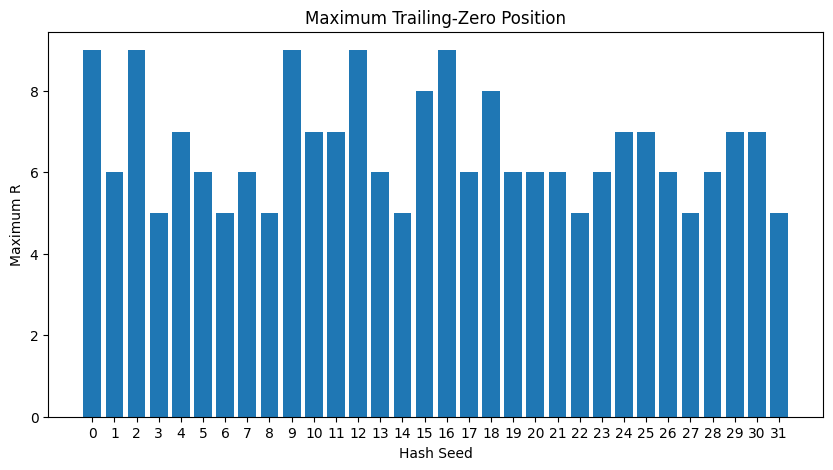

In [ ]:
register_df = pd.DataFrame({
    "Hash Seed": range(len(all_registers)),
    "Maximum Trailing Zeros (R)": all_registers
})
display(register_df)

plt.figure(figsize=(10, 5))
plt.bar(register_df["Hash Seed"], register_df["Maximum Trailing Zeros (R)"])
plt.xlabel("Hash Seed")
plt.ylabel("Maximum R")
plt.title("Maximum Trailing-Zero Position")
plt.xticks(range(len(all_registers)))
plt.show()


## 16. Memory Concept

**Exact counting:** stores the set of all distinct words.

**Basic FM:** stores only one register (`R`).

**Modified FM:** stores one register per hash function.

Thus, FM-based methods use much less memory than maintaining all unique stream elements, especially for very large streams.


In [ ]:
memory_summary = pd.DataFrame({
    "Approach": ["Exact Set", "Basic FM", "Modified FM"],
    "Conceptual Stored Items/Registers": [
        exact_count, 1, len(all_registers)
    ]
})
display(memory_summary)


,Approach,Conceptual Stored Items/Registers
0,Exact Set,89
1,Basic FM,1
2,Modified FM,32


## 17. Final Result and Observation

In [ ]:
basic_error = abs(fm_estimate - exact_count)
modified_error = abs(modified_estimate - exact_count)

print("=" * 60)
print("FINAL RESULT")
print("=" * 60)
print(f"Exact distinct words   : {exact_count}")
print(f"Basic FM estimate      : {fm_estimate:.2f}")
print(f"Modified FM estimate   : {modified_estimate:.2f}")
print(f"Basic FM error         : {basic_error:.2f}")
print(f"Modified FM error      : {modified_error:.2f}")

if modified_error < basic_error:
    print("\nObservation: Modified FM produced the smaller error on this text stream.")
elif modified_error > basic_error:
    print("\nObservation: Basic FM produced the smaller error on this text stream.")
else:
    print("\nObservation: Both methods produced the same absolute error.")


FINAL RESULT
Exact distinct words   : 89
Basic FM estimate      : 661.92
Modified FM estimate   : 82.74
Basic FM error         : 572.92
Modified FM error      : 6.26

Observation: Modified FM produced the smaller error on this text stream.


## 18. Conclusion

The notebook demonstrates cardinality estimation over a text stream using the Flajolet-Martin algorithm. Basic FM uses one register, while Modified FM uses multiple hash functions and median aggregation.

The experiment compares both probabilistic estimates with the exact distinct-word count and visualizes hash-function variation. FM is useful for large streaming data because it estimates distinct elements without storing every unique element.
